In [1]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import tensorflow as tf
import matplotlib.pyplot as plt
plt.rcParams['axes.unicode_minus']=False     
plt.rcParams['font.size'] = 12

In [2]:
data = np.load('./bert_rep.npz')
y = data['all_labels']
data = data['bert_rep']

In [3]:

from keras.utils import to_categorical
y = to_categorical(y)
X_train, X_test, y_train, y_test  = train_test_split(data, y, test_size=0.2, random_state=42, stratify=y)

In [4]:
from keras.models import Model
from keras.layers import Dense,Input,LSTM,Reshape,Flatten,Conv1D
from keras.optimizers import  Adam
inp = Input((128,128))
temp = LSTM(64)(inp)
temp = Flatten()(temp)
temp = Dense(64,activation='relu')(temp)
temp = Dense(64,activation='relu')(temp)
out = Dense(3,activation='softmax')(temp)
model=Model(inputs=[inp],outputs=[out])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,923 (226.26 KB)

 Trainable params: 57,923 (226.26 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:

model.compile(optimizer=Adam(0.0005), loss='categorical_crossentropy', metrics=['accuracy'])

In [6]:
X_train.shape

(8000, 128, 128)

In [7]:
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/100


d:\ProgramData\anaconda3\envs\keras3\Lib\site-packages\keras\src\models\functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(32, 128, 128))
  warnings.warn(msg)


249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4954 - loss: 0.9715

d:\ProgramData\anaconda3\envs\keras3\Lib\site-packages\keras\src\models\functional.py:238: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(None, 128, 128))
  warnings.warn(msg)


250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.4954 - loss: 0.9714 - val_accuracy: 0.5190 - val_loss: 0.9421
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5371 - loss: 0.9291 - val_accuracy: 0.5680 - val_loss: 0.9162
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5653 - loss: 0.9054 - val_accuracy: 0.5870 - val_loss: 0.8921
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5394 - loss: 0.9319 - val_accuracy: 0.5760 - val_loss: 0.8915
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.5927 - loss: 0.8808 - val_accuracy: 0.6070 - val_loss: 0.8894
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.5855 - loss: 0.8953 - val_accuracy: 0.5785 - val_loss: 0.8806
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.6157 - loss: 0.8554 - val_accuracy: 0.6180 - val_loss: 0.8553
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.6186 - loss: 0.8351 - val_accuracy

In [8]:
model.save_weights('./CNN_model_weights.weights.h5')

In [9]:
mm = 'LSTM'

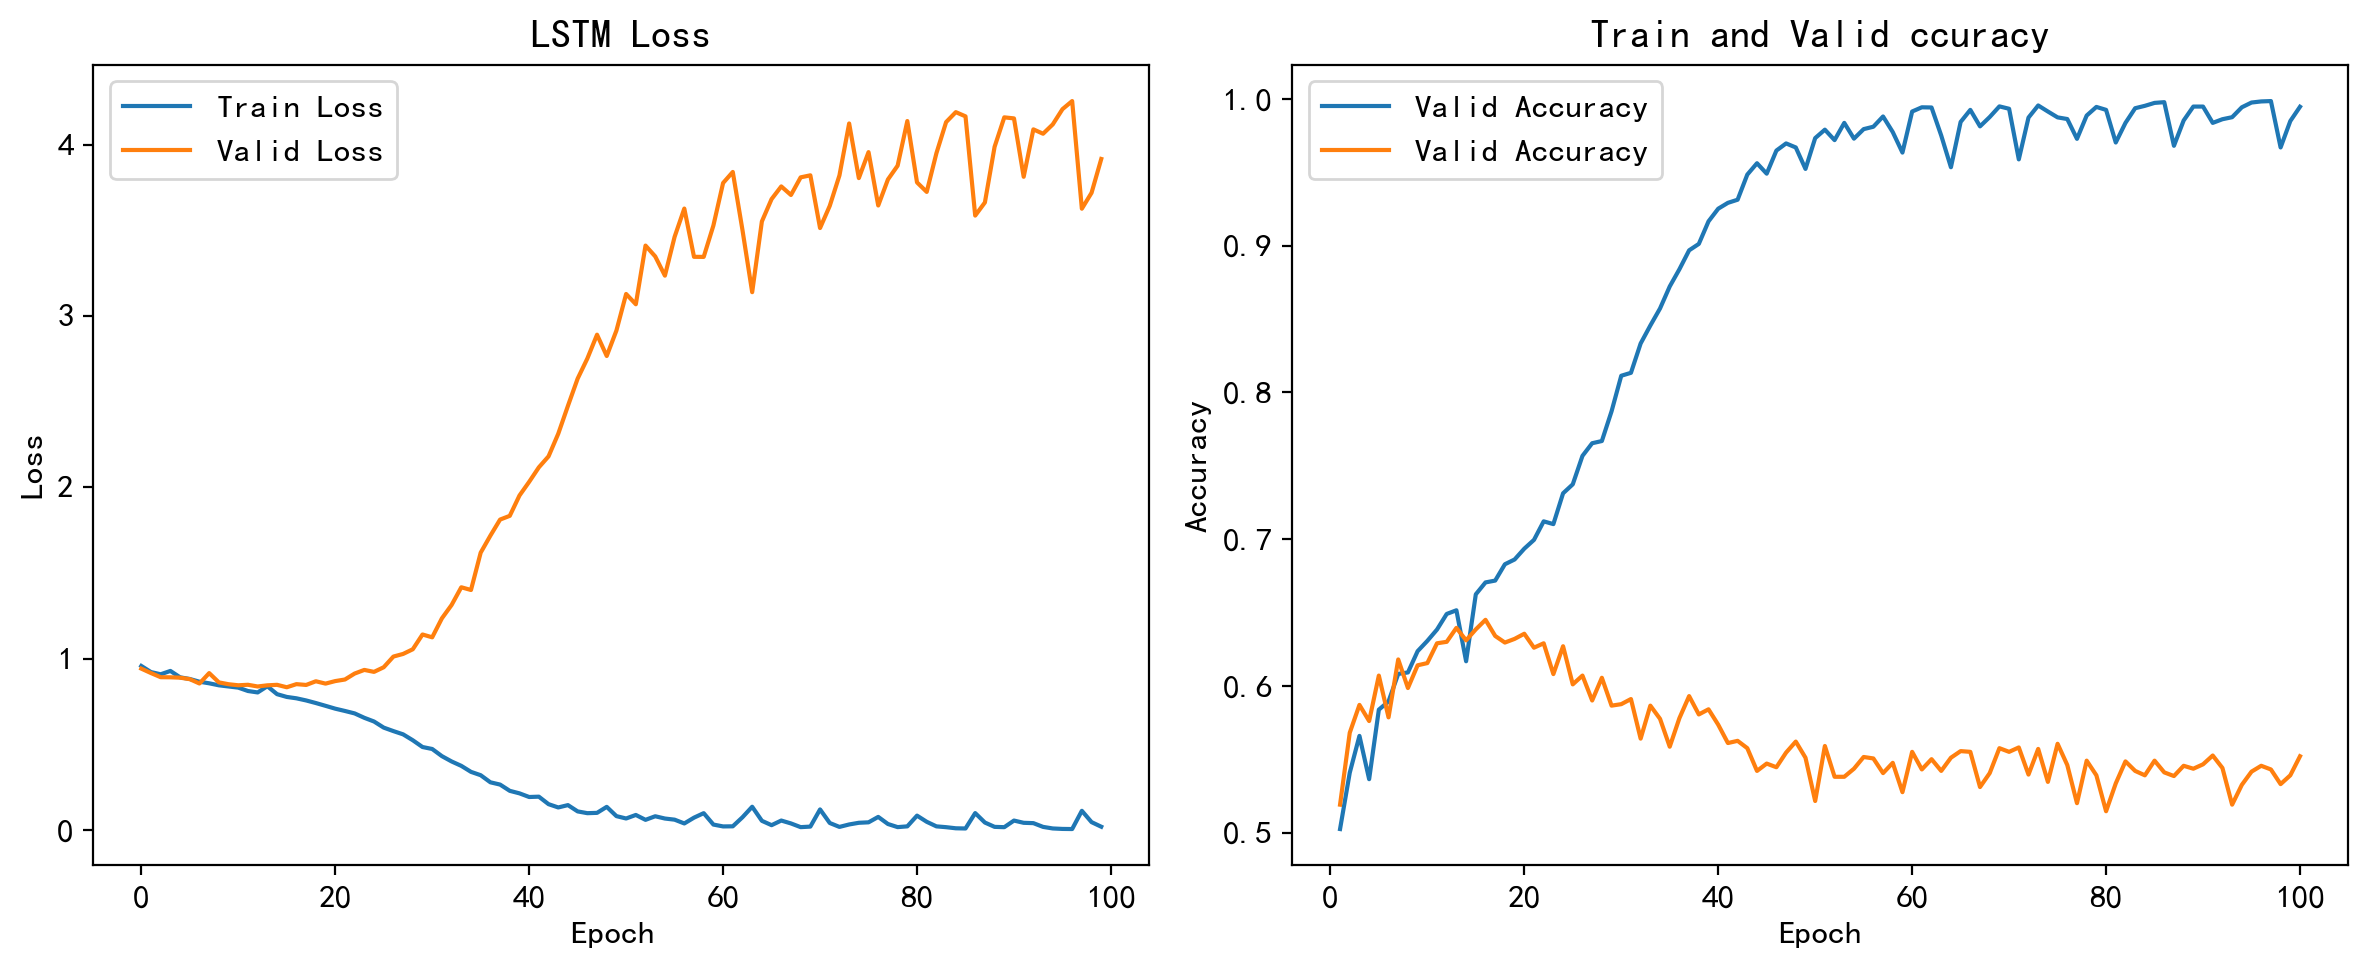

In [10]:
plt.figure(figsize=(12, 5),dpi=200)

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Valid Loss')
plt.xlabel('Epoch ')  
plt.ylabel('Loss')
plt.title(f'{mm} Loss')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(range(1, len(history.history['accuracy']) + 1), history.history['accuracy'], label='Valid Accuracy')  
plt.plot(range(1, len(history.history['val_accuracy']) + 1), history.history['val_accuracy'], label='Valid Accuracy')  
plt.xlabel('Epoch')  # 
plt.ylabel('Accuracy')
plt.title('Train and Valid ccuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score



test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_accuracy:.4f}")


predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)


f1 = f1_score(np.argmax(y_test,axis=1), predicted_classes,average='weighted')
precision = precision_score(np.argmax(y_test,axis=1), predicted_classes,average='weighted')
recall = recall_score(np.argmax(y_test,axis=1), predicted_classes,average='weighted')


print(f"F1 Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")


report = classification_report(np.argmax(y_test,axis=1), predicted_classes, target_names=['Positive', 'Neutral', 'Negative'])
print("Classification Report:")
print(report)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5487 - loss: 4.0112
Test accuracy: 0.5520
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
F1 Score: 0.5445
Precision: 0.5381
Recall: 0.5520
Classification Report:
              precision    recall  f1-score   support

    Positive       0.56      0.55      0.55       805
     Neutral       0.11      0.08      0.10       205
    Negative       0.61      0.65      0.63       990

    accuracy                           0.55      2000
   macro avg       0.43      0.43      0.43      2000
weighted avg       0.54      0.55      0.54      2000



Normalized confusion matrix


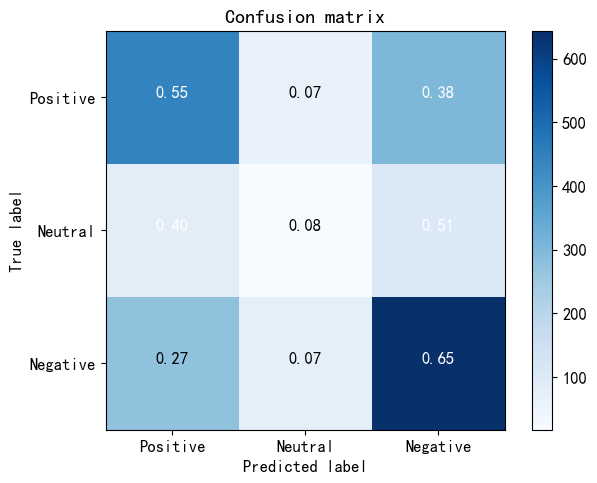

In [14]:
cm = confusion_matrix(np.argmax(y_test,axis=1), predicted_classes,)
from utils import plot_confusion_matrix
plot_confusion_matrix(cm,classes=['Positive', 'Neutral', 'Negative'],normalize=True,title='Confusion matrix')